In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


In [2]:
from pathlib import Path

dataset_candidates = [
    Path("movie_metadata.csv"),
    Path("ASSETS") / "movie_metadata.csv",
]
dataset_path = next(
    (path for path in dataset_candidates if path.is_file()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find movie_metadata.csv beside this notebook or in ASSETS."
    )

df = pd.read_csv(dataset_path)
df.head()

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0


In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (5043, 28)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5043 entries, 0 to 5042
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      5024 non-null   str    
 1   director_name              4939 non-null   str    
 2   num_critic_for_reviews     4993 non-null   float64
 3   duration                   5028 non-null   float64
 4   director_facebook_likes    4939 non-null   float64
 5   actor_3_facebook_likes     5020 non-null   float64
 6   actor_2_name               5030 non-null   str    
 7   actor_1_facebook_likes     5036 non-null   float64
 8   gross                      4159 non-null   float64
 9   genres                     5043 non-null   str    
 10  actor_1_name               5036 non-null   str    
 11  movie_title                5043 non-null   str    
 12  num_voted_users            5043 non-null   int64  
 13  cast_total_facebook_likes  5043 non-null   int64  
 14  act

In [5]:
print("Missing values in each column:")
print(df.isnull().sum().sort_values(ascending=False))

Missing values in each column:
gross                        884
budget                       492
aspect_ratio                 329
content_rating               303
plot_keywords                153
title_year                   108
director_facebook_likes      104
director_name                104
num_critic_for_reviews        50
actor_3_facebook_likes        23
actor_3_name                  23
num_user_for_reviews          21
color                         19
duration                      15
language                      14
actor_2_facebook_likes        13
actor_2_name                  13
facenumber_in_poster          13
actor_1_name                   7
actor_1_facebook_likes         7
country                        5
genres                         0
movie_title                    0
cast_total_facebook_likes      0
movie_imdb_link                0
num_voted_users                0
imdb_score                     0
movie_facebook_likes           0
dtype: int64


In [6]:
print("Duplicate rows if any : ")
print(df.duplicated().sum())


Duplicate rows if any : 
45


In [7]:
df.describe()

,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,gross,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
count,4993.000000,5028.000000,4939.000000,5020.000000,5036.000000,4.159000e+03,5.043000e+03,5043.000000,5030.000000,5022.000000,4.551000e+03,4935.000000,5030.000000,5043.000000,4714.000000,5043.000000
mean,140.194272,107.201074,686.509212,645.009761,6560.047061,4.846841e+07,8.366816e+04,9699.063851,1.371173,272.770808,3.975262e+07,2002.470517,1651.754473,6.442138,2.220403,7525.964505
std,121.601675,25.197441,2813.328607,1665.041728,15020.759120,6.845299e+07,1.384853e+05,18163.799124,2.013576,377.982886,2.061149e+08,12.474599,4042.438863,1.125116,1.385113,19320.445110
min,1.000000,7.000000,0.000000,0.000000,0.000000,1.620000e+02,5.000000e+00,0.000000,0.000000,1.000000,2.180000e+02,1916.000000,0.000000,1.600000,1.180000,0.000000
25%,50.000000,93.000000,7.000000,133.000000,614.000000,5.340988e+06,8.593500e+03,1411.000000,0.000000,65.000000,6.000000e+06,1999.000000,281.000000,5.800000,1.850000,0.000000
50%,110.000000,103.000000,49.000000,371.500000,988.000000,2.551750e+07,3.435900e+04,3090.000000,1.000000,156.000000,2.000000e+07,2005.000000,595.000000,6.600000,2.350000,166.000000
75%,195.000000,118.000000,194.500000,636.000000,11000.000000,6.230944e+07,9.630900e+04,13756.500000,2.000000,326.000000,4.500000e+07,2011.000000,918.000000,7.200000,2.350000,3000.000000
max,813.000000,511.000000,23000.000000,23000.000000,640000.000000,7.605058e+08,1.689764e+06,656730.000000,43.000000,5060.000000,1.221550e+10,2016.000000,137000.000000,9.500000,16.000000,349000.000000


In [8]:
print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())


Categorical columns:
['color', 'director_name', 'actor_2_name', 'genres', 'actor_1_name', 'movie_title', 'actor_3_name', 'plot_keywords', 'movie_imdb_link', 'language', 'country', 'content_rating']


C:\Users\user\AppData\Local\Temp\ipykernel_25248\996438893.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


In [9]:

# Remove duplicate rows and records without a target score.
# Feature missing values are imputed inside the training pipeline after splitting.
df_clean = df.drop_duplicates().dropna(subset=["imdb_score"]).copy()

# Display cleaning results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nFeature values still missing (imputed after the split):",
      df_clean.drop(columns=["imdb_score"]).isnull().sum().sum())

print("Duplicate rows remaining:",
      df_clean.duplicated().sum())

# Display the cleaned dataset
display(df_clean.head())


Original dataset shape: (5043, 28)
Cleaned dataset shape: (4998, 28)

Feature values still missing (imputed after the split): 2676
Duplicate rows remaining: 0


,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0


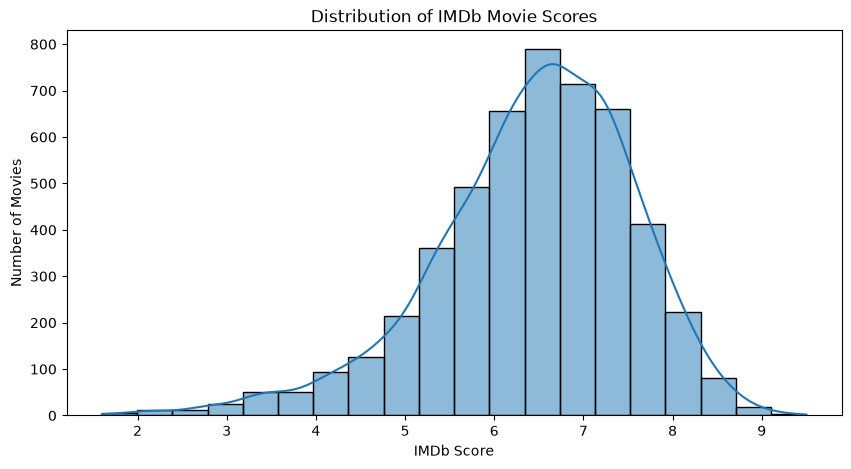

In [10]:

# EDA 1: Distribution of IMDb scores

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="imdb_score",
    bins=20,
    kde=True
)

plt.title("Distribution of IMDb Movie Scores")
plt.xlabel("IMDb Score")
plt.ylabel("Number of Movies")

plt.show()


Classify
Hit        3556
Average    1401
Flop         41
Name: count, dtype: int64


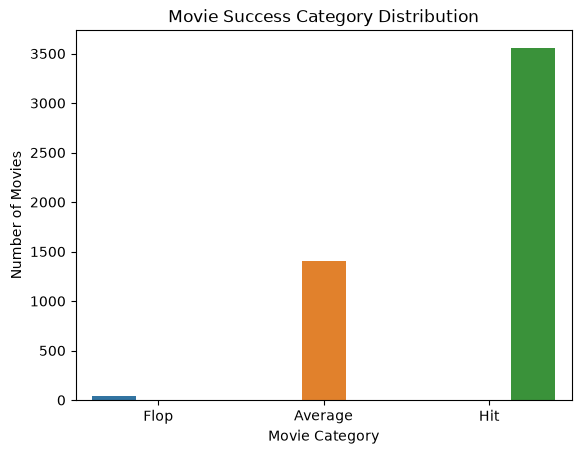

In [11]:

# Create the success category column

df_clean["Classify"] = pd.cut(
    df_clean["imdb_score"],
    bins=[0, 3, 6, 10],
    labels=["Flop", "Average", "Hit"],
    right=False,
    include_lowest=True
)
df_clean = df_clean.dropna(subset=["Classify"]).copy()

# Count movies in each category
print(df_clean["Classify"].value_counts())

# Plot the category distribution
sns.countplot(
    data=df_clean,
    x="Classify",
    hue="Classify",
    order=["Flop", "Average", "Hit"],
    legend=False
)

plt.title("Movie Success Category Distribution")
plt.xlabel("Movie Category")
plt.ylabel("Number of Movies")
plt.show()


Correlation of numerical features with IMDb score:


imdb_score                   1.000000
num_voted_users              0.411299
num_critic_for_reviews       0.307226
num_user_for_reviews         0.292745
duration                     0.262618
movie_facebook_likes         0.249604
gross                        0.198417
director_facebook_likes      0.171564
cast_total_facebook_likes    0.085091
actor_2_facebook_likes       0.082400
actor_1_facebook_likes       0.075952
aspect_ratio                 0.060266
actor_3_facebook_likes       0.051683
budget                       0.031061
facenumber_in_poster        -0.064403
title_year                  -0.207591
Name: imdb_score, dtype: float64

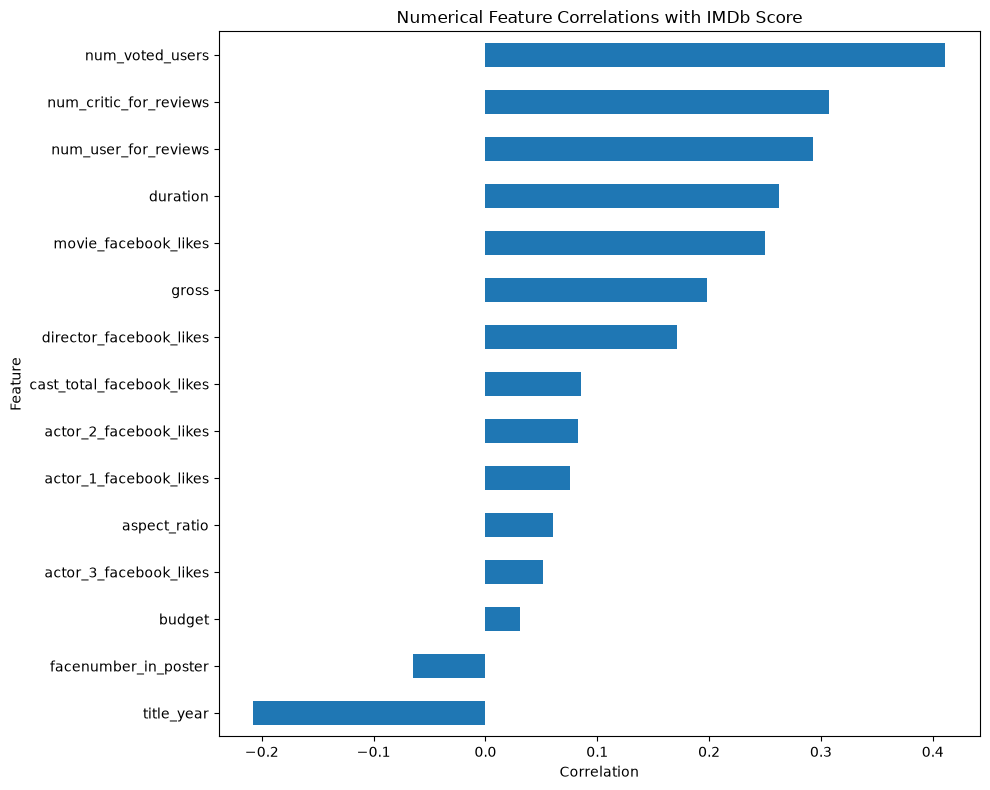

In [12]:

# Select numerical columns
numeric_df = df_clean.select_dtypes(include=np.number)

# Calculate correlations with IMDb score
correlations = numeric_df.corr()["imdb_score"].sort_values(
    ascending=False
)

print("Correlation of numerical features with IMDb score:")
display(correlations)

# Plot the correlations
correlations.drop("imdb_score").sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)

plt.title("Numerical Feature Correlations with IMDb Score")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



In [13]:

# STEP 8: Explore categorical features

# Display available categorical columns
categorical_cols = df_clean.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

# Examine the most common genres
print("\nTop 10 genres:")
print(df_clean["genres"].value_counts().head(10))

# Examine the most common countries
print("\nTop 10 countries:")
print(df_clean["country"].value_counts().head(10))

# Examine the most common languages
print("\nTop 10 languages:")
print(df_clean["language"].value_counts().head(10))

# Examine content ratings
print("\nContent rating distribution:")
print(df_clean["content_rating"].value_counts().head(10))


Categorical columns:
['color', 'director_name', 'actor_2_name', 'genres', 'actor_1_name', 'movie_title', 'actor_3_name', 'plot_keywords', 'movie_imdb_link', 'language', 'country', 'content_rating']

Top 10 genres:
genres
Drama                          235
Comedy                         205
Comedy|Drama                   189
Comedy|Drama|Romance           187
Comedy|Romance                 158
Drama|Romance                  151
Crime|Drama|Thriller           100
Horror                          70
Action|Crime|Drama|Thriller     67
Action|Crime|Thriller           64
Name: count, dtype: int64

Top 10 countries:
country
USA          3773
UK            443
France        154
Canada        124
Germany        96
Australia      55
India          34
Spain          33
China          28
Italy          23
Name: count, dtype: int64

Top 10 languages:
language
English      4662
French         73
Spanish        40
Hindi          28
Mandarin       24
German         19
Japanese       17
Russian        1

C:\Users\user\AppData\Local\Temp\ipykernel_25248\697813268.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(


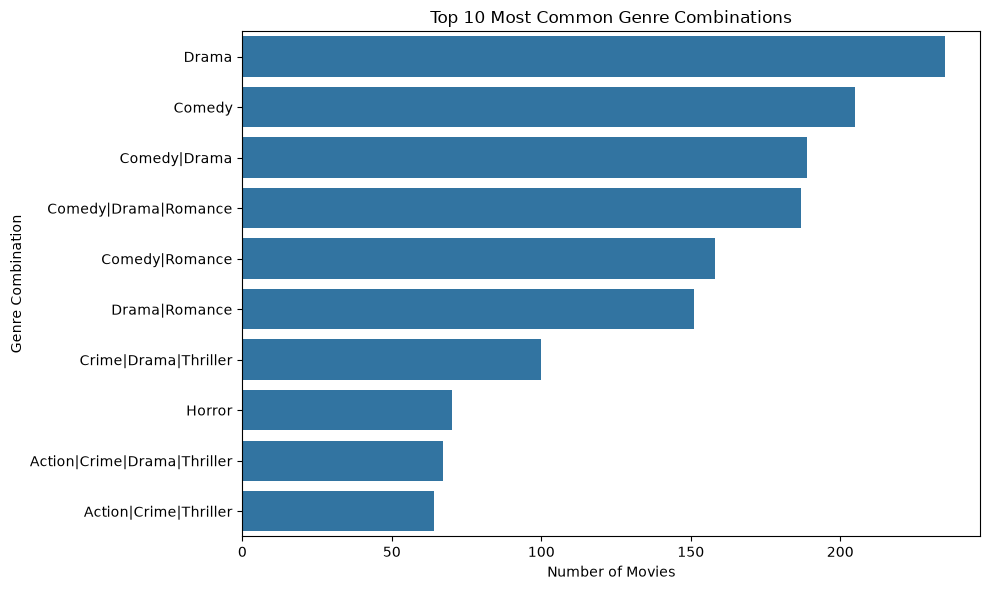

In [14]:

# Find the 10 most frequent genre combinations
top_genres = df_clean["genres"].value_counts().head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Most Common Genre Combinations")
plt.xlabel("Number of Movies")
plt.ylabel("Genre Combination")
plt.tight_layout()
plt.show()


In [15]:

# STEP 10: Analyze IMDb scores by individual genre

# Make a copy for genre analysis
genre_df = df_clean[["genres", "imdb_score"]].copy()

# Split genre combinations into individual genres
genre_df["genres"] = genre_df["genres"].str.split("|")

# Put each genre on a separate row
genre_df = genre_df.explode("genres")

# Remove extra spaces
genre_df["genres"] = genre_df["genres"].str.strip()

# Calculate average IMDb score for each genre
genre_ratings = (
    genre_df.groupby("genres")["imdb_score"]
    .mean()
    .sort_values(ascending=False)
)

print("Average IMDb score by genre:")
display(genre_ratings.round(2))


Average IMDb score by genre:


genres
Film-Noir      7.63
News           7.53
Documentary    7.18
Biography      7.15
History        7.08
War            7.07
Drama          6.76
Western        6.70
Sport          6.60
Animation      6.58
Crime          6.56
Musical        6.51
Mystery        6.49
Romance        6.45
Adventure      6.44
Music          6.41
Short          6.38
Thriller       6.31
Fantasy        6.31
Sci-Fi         6.28
Family         6.25
Action         6.24
Comedy         6.19
Horror         5.83
Reality-TV     4.75
Game-Show      2.90
Name: imdb_score, dtype: float64

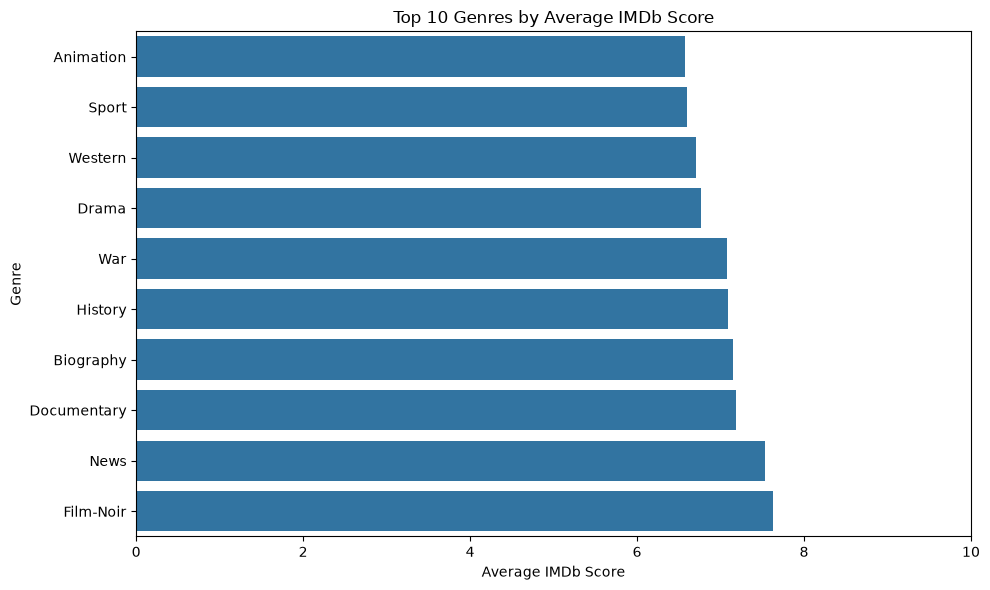

In [16]:

# Plot the 10 highest-rated genres by average IMDb score

top_rated_genres = genre_ratings.head(10).sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_rated_genres.values,
    y=top_rated_genres.index
)

plt.title("Top 10 Genres by Average IMDb Score")
plt.xlabel("Average IMDb Score")
plt.ylabel("Genre")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()


In [17]:

# STEP 12: Define the target variable

# X contains prediction features; y contains the success category.

target = "Classify"

# Remove target and information unavailable before release
drop_cols = [
    "Classify",
    "imdb_score",
    "movie_title",
    "director_name",
    "actor_1_name",
    "actor_2_name",
    "actor_3_name",
    "plot_keywords",
    "movie_imdb_link",
    "num_voted_users",
    "num_user_for_reviews",
    "num_critic_for_reviews",
    "gross"
]

X = df_clean.drop(columns=drop_cols, errors="ignore")
y = df_clean[target]

# Check the result
print("Input features (X):", X.shape)
print("Target variable (y):", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

print("\nTarget categories:")
print(y.value_counts())


Input features (X): (4998, 16)
Target variable (y): (4998,)

Input columns:
['color', 'duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_1_facebook_likes', 'genres', 'cast_total_facebook_likes', 'facenumber_in_poster', 'language', 'country', 'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes', 'aspect_ratio', 'movie_facebook_likes']

Target categories:
Classify
Hit        3556
Average    1401
Flop         41
Name: count, dtype: int64


In [18]:

# STEP 13: Split the data into training and testing sets


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the shapes
print("Training input data:", X_train.shape)
print("Testing input data:", X_test.shape)

print("Training target data:", y_train.shape)
print("Testing target data:", y_test.shape)


Training input data: (3998, 16)
Testing input data: (1000, 16)
Training target data: (3998,)
Testing target data: (1000,)


In [19]:

# STEP 14.1: Identify numerical and categorical columns

# Numerical columns contain numbers
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Categorical columns contain text
categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Numerical features:")
print(numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)


Number of numerical features: 11
Numerical features:
['duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_1_facebook_likes', 'cast_total_facebook_likes', 'facenumber_in_poster', 'budget', 'title_year', 'actor_2_facebook_likes', 'aspect_ratio', 'movie_facebook_likes']

Number of categorical features: 5
Categorical features:
['color', 'genres', 'language', 'country', 'content_rating']


In [20]:
# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


# Models

In [21]:
# XGBoost is already available in the active notebook environment.

In [22]:
from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline



from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [23]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )
}

print("Total models to compare:", len(models))

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)


Total models to compare: 5


In [24]:
# Fit each algorithm on the train split and evaluate on the same holdout.
results = []
trained_models = {}

rf_feature_columns = [
    "director_name",
    "duration",
    "genres",
    "actor_1_name",
    "actor_2_name",
    "actor_3_name",
    "budget",
    "title_year",
    "language",
    "country",
]
rf_person_name_features = [
    "director_name",
    "actor_1_name",
    "actor_2_name",
    "actor_3_name",
]

for name, classifier in models.items():
    print("Training:", name)

    if name == "Random Forest":
        model_x_train = df_clean.loc[X_train.index, rf_feature_columns]
        model_x_test = df_clean.loc[X_test.index, rf_feature_columns]
        numeric_columns = model_x_train.select_dtypes(include=np.number).columns.tolist()
        categorical_columns = [
            column
            for column in model_x_train.select_dtypes(exclude=np.number).columns
            if column not in rf_person_name_features
        ]
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
        ])
        person_name_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=2)),
        ])
        model_preprocessor = ColumnTransformer([
            ("numeric", numeric_pipeline, numeric_columns),
            ("categorical", categorical_pipeline, categorical_columns),
            ("person_names", person_name_pipeline, rf_person_name_features),
        ])
        X_rf_test = model_x_test
    else:
        model_x_train = X_train
        model_x_test = X_test
        model_preprocessor = preprocessor

    model_pipeline = Pipeline([
        ("preprocessor", clone(model_preprocessor)),
        ("classifier", classifier),
    ])
    model_pipeline.fit(model_x_train, y_train_encoded)
    predictions = model_pipeline.predict(model_x_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test_encoded, predictions) * 100, 2),
        "Precision (%)": round(
            precision_score(y_test_encoded, predictions, average="macro", zero_division=0) * 100,
            2,
        ),
        "Balanced Accuracy (%)": round(
            balanced_accuracy_score(y_test_encoded, predictions) * 100, 2
        ),
        "Macro F1 (%)": round(
            f1_score(y_test_encoded, predictions, average="macro", zero_division=0) * 100,
            2,
        ),
    })
    trained_models[name] = model_pipeline

results_df = pd.DataFrame(results).sort_values(
    by="Macro F1 (%)", ascending=False
).reset_index(drop=True)


Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: KNN
Training: XGBoost


In [25]:

# Check how many movies belong to each category

print("Movie category counts:")
print(y.value_counts())

print("\nMovie category percentages:")
print(
    (y.value_counts(normalize=True) * 100).round(2)
)


Movie category counts:
Classify
Hit        3556
Average    1401
Flop         41
Name: count, dtype: int64

Movie category percentages:
Classify
Hit        71.15
Average    28.03
Flop        0.82
Name: proportion, dtype: float64


In [26]:

# Check how many unique values each categorical column contains

categorical_cols = X_train.select_dtypes(
    exclude="number"
).columns

for col in categorical_cols:
    print(
        f"{col}: {X_train[col].nunique()} unique values"
    )


color: 2 unique values
genres: 817 unique values
language: 42 unique values
country: 63 unique values
content_rating: 17 unique values


In [27]:
("encoder", OneHotEncoder(
    handle_unknown="ignore",
    min_frequency=10
))

('encoder', OneHotEncoder(handle_unknown='ignore', min_frequency=10))

In [28]:
from sklearn.metrics import classification_report

# Select the current best model: XGBoost
best_model = trained_models["XGBoost"]

# Predict on test data
predictions = best_model.predict(X_test)

# Convert numeric predictions back to category names
predicted_labels = label_encoder.inverse_transform(predictions)

# Show detailed evaluation
print(classification_report(
    y_test,
    predicted_labels,
    labels=["Flop", "Average", "Hit"],
    zero_division=0
))

              precision    recall  f1-score   support

        Flop       0.00      0.00      0.00         8
     Average       0.68      0.52      0.59       280
         Hit       0.82      0.91      0.86       712

    accuracy                           0.79      1000
   macro avg       0.50      0.48      0.48      1000
weighted avg       0.78      0.79      0.78      1000



Random Forest - Reduced-input Classification Report\n
              precision    recall  f1-score   support

        Flop       0.00      0.00      0.00         8
     Average       0.55      0.54      0.55       280
         Hit       0.82      0.84      0.83       712

    accuracy                           0.75      1000
   macro avg       0.46      0.46      0.46      1000
weighted avg       0.74      0.75      0.74      1000



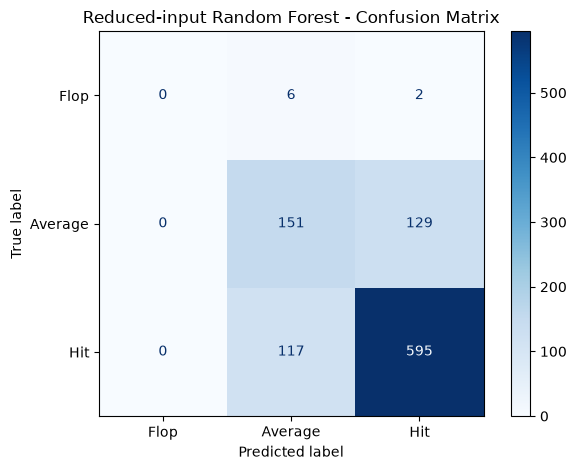

In [29]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# This is the same reduced-input Random Forest used by the deployed site.
rf_model = trained_models["Random Forest"]
rf_predictions = rf_model.predict(X_rf_test)
rf_predicted_labels = label_encoder.inverse_transform(rf_predictions)

print("Random Forest - Reduced-input Classification Report\\n")
print(classification_report(
    y_test,
    rf_predicted_labels,
    labels=["Flop", "Average", "Hit"],
    zero_division=0,
))

cm = confusion_matrix(
    y_test,
    rf_predicted_labels,
    labels=["Flop", "Average", "Hit"],
)
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Flop", "Average", "Hit"],
)
confusion_display.plot(cmap="Blues", values_format="d")
plt.title("Reduced-input Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


# FLop ACCUracy Increase

In [30]:
print("Training data:")
print(y_train.value_counts())

print("\nTraining data percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest data:")
print(y_test.value_counts())

Training data:
Classify
Hit        2844
Average    1121
Flop         33
Name: count, dtype: int64

Training data percentages:
Classify
Hit        71.14
Average    28.04
Flop        0.83
Name: proportion, dtype: float64

Test data:
Classify
Hit        712
Average    280
Flop         8
Name: count, dtype: int64


In [31]:
print("Oversampling skipped: Windows Application Control blocked a required scikit-learn DLL.")

Oversampling skipped: Windows Application Control blocked a required scikit-learn DLL.


In [32]:
if "results_df" not in globals() or results_df.empty:
    raise RuntimeError("Run the model-training and evaluation cell before comparing models.")

comparison_table = results_df.copy()
display(comparison_table)


,Model,Accuracy (%),Precision (%),Balanced Accuracy (%),Macro F1 (%)
0,XGBoost,79.3,50.11,47.67,48.48
1,Random Forest,74.6,45.69,45.83,45.76
2,KNN,72.9,44.40,44.75,44.57
3,Logistic Regression,63.5,45.76,45.19,43.12
4,Decision Tree,69.9,42.73,43.49,43.04
